# 02 · Efficiency metrics and SLA attainment

**Data:** **[REAL]** the 2023 ticket export (2,330 tickets, 2023-01-02 to
2023-12-30, snapshot 2024-01-04 05:39). SLA outcomes are recomputed from timestamps in SQL.
No synthetic data is used in this notebook.

*Part of the Support SLA & Capacity Review (full story: `reports/report.html`). Inputs are rebuilt by
`python run.py`; this notebook re-runs top to bottom with `make notebooks`.*

In [1]:
import json, pandas as pd, plotly.io as pio
pio.renderers.default = "notebook_connected+png"     # interactive in HTML export, static PNG fallback for GitHub
pio.renderers["png"].width, pio.renderers["png"].height = 1000, None
from support_ops import charts as C
from support_ops.data import load_processed, load_tickets
from support_ops.config import load_config, REPO_ROOT
kn = json.load(open(REPO_ROOT / "reports" / "key_numbers.json"))
cfg = load_config()

# --- also used in this notebook ----------------------------------------------
import numpy as np
from scipy import stats
from support_ops import kpis, rca, synth
from support_ops.sql import connect, run_sql_file
goal, aged_days = cfg["sla"]["goal_attainment"], cfg["sla"]["aged_backlog_days"]
pd.set_option("display.max_colwidth", 120)

## TL;DR

- **The SLA that fell is resolution, not response.** **[REAL]** Resolution SLA attainment fell from
  73.5% in Q1 to 60.6% in Q4 (Q4 95% CI
  56.6%-64.5%), and from
  76.3% of January's tickets to 59.7% of December's. Response
  SLA held at 87.2% for the year and was better in H2 (89.1%) than in H1
  (85.4%).
- **A growing slow tail, not slower handling across the board.** **[REAL]** The median resolution time moved
  only from 20.3 h (H1) to 23.4 h (H2), but the
  90th percentile went from 46.5 h in January to
  104.0 h in December, and the share of resolved tickets taking more
  than 48 h doubled (11.2% → 23.3%).
- **It is everywhere, not in a hotspot.** **[REAL]** Of 1,268 segment
  combinations tested per SLA, 0 survive the false-discovery-rate
  check for resolution, and the resolved-late share rose in every channel, priority, topic, tier, product group
  and agent. Priority (p = 0.29) and topic (p = 0.501)
  make no difference to resolution SLA. Agents range from 61.7% to
  76.3% with overlapping intervals (p = 0.044, not
  significant once the number of tests is accounted for), and 7 of 8
  declined from H1 to H2.
- **Response breaches are pickup failures, not queueing.** **[REAL]** For response SLA only Phone (2-minute
  target, 24.2% breach rate) and its sub-segments survive the check
  (5 combinations, one finding). Email breaches are a median
  209.8 minutes late, against 2.11 for
  chat and 1.76 for phone, and only
  9.7% of email breaches are near-misses (60 minutes late or less): late
  emails were missed, not queued.

In [2]:
# Every number in the TL;DR above, read from reports/key_numbers.json
tldr = {
    'Resolution SLA Q1': f"{kn['resolution_sla_q1']:.1%}",
    'Resolution SLA Q4': f"{kn['resolution_sla_q4']:.1%}",
    'Resolution SLA Q4, 95% CI low': f"{kn['resolution_sla_q4_lo']:.1%}",
    'Resolution SLA Q4, 95% CI high': f"{kn['resolution_sla_q4_hi']:.1%}",
    'Resolution SLA January': f"{kn['resolution_sla_jan']:.1%}",
    'Resolution SLA December': f"{kn['resolution_sla_dec']:.1%}",
    'Response SLA 2023': f"{kn['response_sla_2023']:.1%}",
    'Response SLA H1': f"{kn['response_sla_h1']:.1%}",
    'Response SLA H2': f"{kn['response_sla_h2']:.1%}",
    'Median resolution time H1 (h)': f"{kn['resolution_median_h_h1']:.1f}",
    'Median resolution time H2 (h)': f"{kn['resolution_median_h_h2']:.1f}",
    '90th percentile resolution time, Jan (h)': f"{kn['resolution_p90_h_jan']:.1f}",
    '90th percentile resolution time, Dec (h)': f"{kn['resolution_p90_h_dec']:.1f}",
    'Resolved tickets taking > 48 h, H1': f"{kn['share_resolved_over_48h_h1']:.1%}",
    'Resolved tickets taking > 48 h, H2': f"{kn['share_resolved_over_48h_h2']:.1%}",
    'Segment combinations tested per SLA': f"{kn['hotspots_tested_per_sla']:,}",
    'Resolution combinations surviving FDR': f"{kn['hotspots_significant_resolution']}",
    'Response combinations surviving FDR': f"{kn['hotspots_significant_response']}",
    'Priority vs resolution SLA, p': f"{kn['rca_priority_p_resolution']}",
    'Topic vs resolution SLA, p': f"{kn['rca_topic_p_resolution']}",
    'Agent vs resolution SLA, p': f"{kn['rca_agent_p_resolution']}",
    'Agent resolution SLA, lowest': f"{kn['agent_resolution_sla_min']:.1%}",
    'Agent resolution SLA, highest': f"{kn['agent_resolution_sla_max']:.1%}",
    'Agents whose resolution SLA fell H1 -> H2': f"{kn['agents_declined_h1_to_h2']} of 8",
    'Phone response breach rate': f"{kn['phone_response_breach_rate']:.1%}",
    'Email breaches: median minutes late': f"{kn['late_email_breach_median_min_late']:.1f}",
    'Chat breaches: median minutes late': f"{kn['late_chat_breach_median_min_late']:.2f}",
    'Phone breaches: median minutes late': f"{kn['late_phone_breach_median_min_late']:.2f}",
    'Email breaches that are near-misses': f"{kn['email_breach_near_miss_share']:.1%}",
}
for label, value in tldr.items():
    print(f"{label:<44}{value}")

Resolution SLA Q1                           73.5%
Resolution SLA Q4                           60.6%
Resolution SLA Q4, 95% CI low               56.6%
Resolution SLA Q4, 95% CI high              64.5%
Resolution SLA January                      76.3%
Resolution SLA December                     59.7%
Response SLA 2023                           87.2%
Response SLA H1                             85.4%
Response SLA H2                             89.1%
Median resolution time H1 (h)               20.3
Median resolution time H2 (h)               23.4
90th percentile resolution time, Jan (h)    46.5
90th percentile resolution time, Dec (h)    104.0
Resolved tickets taking > 48 h, H1          11.2%
Resolved tickets taking > 48 h, H2          23.3%
Segment combinations tested per SLA         1,268
Resolution combinations surviving FDR       0
Response combinations surviving FDR         5
Priority vs resolution SLA, p               0.29
Topic vs resolution SLA, p                  0.501
Agent vs res

## Question

The Director's words were *"SLA attainment is falling … did efficiency go down?"* Two testable questions from
`docs/01_request_and_scope.md`:

- **Q1.** Which SLA is falling - **response** (first reply on time) or **resolution** (solved on time)? By how
  much, since when, and is the fall larger than noise?
- **Q3.** Did handling speed fall everywhere, or is it concentrated in specific channels, topics, priorities,
  tiers, agents or time slots?

## Data

All tables are **[REAL]** and are rebuilt from the export by `python run.py`:

| table | built by | one row per |
|---|---|---|
| `fct_tickets` | `sql/00_fct_tickets.sql` | ticket, with response / resolution SLA recomputed |
| `kpi_monthly` | `sql/01_kpi_monthly.sql` | month the ticket was created |
| `kpi_by_dimension` | `sql/02_kpi_by_dimension.sql` | dimension × segment (channel, priority, topic, …) |
| `kpi_hotspots` | `sql/03_breach_hotspots.sql`, then Benjamini-Hochberg in `support_ops.kpis` | SLA × combination of 1-3 dimensions with ≥ 30 tickets |
| `kpi_agent_scorecard` | `sql/05_agent_scorecard.sql` | agent (current ticket owner) |
| `rca_heterogeneity`, `rca_breach_lateness` | `support_ops.rca` | test / channel |
| `dq_checks` | `sql/90_data_quality_checks.sql` | data-quality check |

In [3]:
fct = load_tickets()
monthly = load_processed("kpi_monthly")
bydim = load_processed("kpi_by_dimension")
hot = load_processed("kpi_hotspots")
agents = load_processed("kpi_agent_scorecard")
het = load_processed("rca_heterogeneity")
lateness = load_processed("rca_breach_lateness")
dq = load_processed("dq_checks")

pd.Series({"fct_tickets": len(fct), "kpi_monthly": len(monthly), "kpi_by_dimension": len(bydim),
           "kpi_hotspots": len(hot), "kpi_agent_scorecard": len(agents), "rca_heterogeneity": len(het),
           "rca_breach_lateness": len(lateness), "dq_checks": len(dq)}, name="rows").to_frame()

,rows
fct_tickets,2330
kpi_monthly,12
kpi_by_dimension,38
kpi_hotspots,2536
kpi_agent_scorecard,8
rca_heterogeneity,12
rca_breach_lateness,3
dq_checks,31


## Method

**Definitions** (full list in `docs/02_metric_definitions.md`):

- **Response SLA met** = first reply at or before the response deadline (email 60
  min; chat and phone 2 min). A ticket with no reply whose deadline passed
  before the snapshot is a breach. Two tickets whose first reply is time-stamped before creation are left out.
- **Resolution SLA met** = resolved at or before the resolution deadline (chat 24 h;
  email and phone 48 h). A ticket still unresolved and past its deadline at
  the snapshot is a breach ("never resolved").
- **Attainment** = tickets meeting the target ÷ tickets that can be evaluated. Months and quarters are cohorts by
  **creation** date.
- **Resolved-late share** = tickets resolved after their deadline as a share of **all** tickets created in the
  period (not of resolved tickets only).

**Why recompute.** The export's own SLA flags contradict its timestamps on 14
response tickets and 1 resolution ticket, so every SLA number here comes from
the timestamps (SQL below).

**Confidence intervals.** Each attainment carries a Wilson 95% interval: the range of true rates consistent with
the observed count. It behaves well for small groups and for rates near 0% or 100%. When two segments' intervals
overlap a lot, the difference may be noise.

**Hotspots and the multiple-testing trap.** We scan every combination of one to three of seven dimensions
(weekday, 6-hour band, channel, priority, topic, tier, product group) with at least 30 tickets:
1,268 combinations per SLA. Each is tested for breaching more often than all tickets
(one-sided binomial test). At p < 0.05, about 63 would pass by chance alone if the tests were
independent. The Benjamini-Hochberg false-discovery-rate (FDR) correction ranks the p-values and keeps only
combinations that stay significant after allowing for how many tests were run, so that about 5% of the
combinations it flags are expected to be false alarms.

**Segment tests.** Chi-square tests of independence ask whether attainment differs between agents, priorities,
topics or channels by more than chance. Twelve such tests are run (6 dimensions × 2 SLAs), so they get the same
FDR treatment.

In [4]:
def show_sql(name, start=None, end=None):
    """Print a file from sql/, or only the part from marker `start` up to marker `end`."""
    text = (REPO_ROOT / "sql" / name).read_text()
    i = text.index(start) if start else 0
    print(text[i:text.index(end, i) if end else None].rstrip())


# SLA outcomes as defined in the cleaning SQL (recomputed from timestamps; raw flags kept only for reconciliation)
show_sql("00_fct_tickets.sql", start="    -- RESPONSE SLA (recomputed)", end="    -- raw flags kept")

    -- RESPONSE SLA (recomputed). NULL = not evaluable (invalid timestamp or not yet due)
    CASE
        WHEN first_response_at IS NULL AND response_due_at <= snapshot_at THEN FALSE
        WHEN first_response_at IS NULL THEN NULL
        WHEN frt_min_raw < 0 THEN NULL
        ELSE first_response_at <= response_due_at
    END                                                       AS response_sla_met,

    -- RESOLUTION SLA (recomputed). Unresolved and past due at snapshot = breached
    CASE
        WHEN resolved_at IS NULL AND resolution_due_at <= snapshot_at THEN FALSE
        WHEN resolved_at IS NULL THEN NULL
        ELSE resolved_at <= resolution_due_at
    END                                                       AS resolution_sla_met,

    CASE
        WHEN resolved_at IS NOT NULL AND resolved_at <= resolution_due_at THEN 'Resolved within SLA'
        WHEN resolved_at IS NOT NULL THEN 'Resolved late'
        WHEN resolution_due_at <= snapshot_at THEN 'Unresolved, overdue'
     

In [5]:
# The SLA policy is not documented; it is read off the deadlines. Targets depend on channel only, not priority.
con = connect()     # DuckDB with fct_tickets_path -> data/processed/fct_tickets.parquet
con.sql('''
    SELECT channel,
           min(response_target_min) AS response_target_min, max(response_target_min) AS response_target_max,
           min(resolution_target_h) AS resolution_target_h_min, max(resolution_target_h) AS resolution_target_h_max,
           count(DISTINCT priority) AS priorities, count(*) AS tickets
    FROM read_parquet(getvariable('fct_tickets_path'))
    GROUP BY channel ORDER BY channel
''').df()

,channel,response_target_min,response_target_max,resolution_target_h_min,resolution_target_h_max,priorities,tickets
0,Chat,2.0,2.0,24.0,24.0,3,850
1,Email,60.0,60.0,48.0,48.0,3,1234
2,Phone,2.0,2.0,48.0,48.0,3,246


In [6]:
# Attainment by quarter, straight from SQL; Wilson interval recomputed independently with scipy
quarterly = con.sql('''
    SELECT created_quarter                                          AS quarter,
           count_if(response_sla_met) / count(response_sla_met)     AS response_attainment,
           count(resolution_sla_met)                                AS resolution_evaluable,
           count_if(resolution_sla_met)                             AS resolution_met,
           count_if(resolution_sla_met) / count(resolution_sla_met) AS resolution_attainment
    FROM read_parquet(getvariable('fct_tickets_path'))
    GROUP BY ALL ORDER BY ALL
''').df().set_index("quarter")
ci = [stats.binomtest(int(x), int(n)).proportion_ci(method="wilson")
      for x, n in zip(quarterly.resolution_met, quarterly.resolution_evaluable)]
quarterly["resolution_ci_lo"], quarterly["resolution_ci_hi"] = [c.low for c in ci], [c.high for c in ci]
quarterly.round(4)

,response_attainment,resolution_evaluable,resolution_met,resolution_attainment,resolution_ci_lo,resolution_ci_hi
quarter,,,,,,
Q1,0.8632,586,431.0,0.7355,0.6983,0.7696
Q2,0.8451,595,403.0,0.6773,0.6387,0.7136
Q3,0.8911,560,355.0,0.6339,0.5932,0.6728
Q4,0.8913,589,357.0,0.6061,0.5661,0.6448


In [7]:
# Hotspot scan: every 1- to 3-way combination with >= 30 tickets (the CUBE), compared with the overall rate
show_sql("03_breach_hotspots.sql", start="cube AS (")

cube AS (
    SELECT
        sla_type, day_of_week, hour_band, channel, priority, topic, agent_group, product_group,
        GROUPING(day_of_week, hour_band, channel, priority, topic, agent_group, product_group) AS gid,
        count(*)            AS n,
        count_if(breached)  AS breaches
    FROM sla
    GROUP BY sla_type, CUBE (day_of_week, hour_band, channel, priority, topic, agent_group, product_group)
),
labelled AS (
    SELECT *,
        -- number of dimensions in the combination = 7 - bits set in the grouping id
        7 - bit_count(gid::INTEGER)                                AS n_dims,
        concat_ws(' + ',
            day_of_week, hour_band, channel, priority || ' priority',
            CASE WHEN topic = 'Other' THEN 'Other topic' ELSE topic END, agent_group,
            CASE WHEN product_group = 'Other' THEN 'Other product' ELSE product_group END) AS combination
    FROM cube
)
SELECT
    l.sla_type, l.n_dims, l.combination,
    l.day_of_week, l.hour_band, l.channel

In [8]:
# Benjamini-Hochberg adjustment applied to the hotspot p-values (support_ops/kpis.py)
import inspect
print(inspect.getsource(kpis.benjamini_hochberg))

def benjamini_hochberg(p: np.ndarray) -> np.ndarray:
    """BH-adjusted p-values (q-values), monotone, capped at 1."""
    p = np.asarray(p, dtype=float)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(n)
    out[order] = np.minimum(q, 1.0)
    return out



In [9]:
# The cached KPI tables are exactly what the SQL files produce today
for name, sql_file in [("kpi_monthly", "01_kpi_monthly.sql"), ("kpi_by_dimension", "02_kpi_by_dimension.sql"),
                       ("kpi_agent_scorecard", "05_agent_scorecard.sql")]:
    pd.testing.assert_frame_equal(run_sql_file(sql_file), load_processed(name), check_dtype=False)
    print(f"sql/{sql_file:<25} re-run == data/processed/{name}.parquet")
# hotspot rows tie on excess breaches, so compare in a fixed order
keys = ["sla_type", "n_dims", "day_of_week", "hour_band", "channel", "priority", "topic", "agent_group",
        "product_group"]
fresh = run_sql_file("03_breach_hotspots.sql")
pd.testing.assert_frame_equal(fresh.sort_values(keys).reset_index(drop=True),
                              hot[fresh.columns].sort_values(keys).reset_index(drop=True), check_dtype=False)
print("sql/03_breach_hotspots.sql      re-run == data/processed/kpi_hotspots.parquet (SQL columns)")

sql/01_kpi_monthly.sql        re-run == data/processed/kpi_monthly.parquet


sql/02_kpi_by_dimension.sql   re-run == data/processed/kpi_by_dimension.parquet
sql/05_agent_scorecard.sql    re-run == data/processed/kpi_agent_scorecard.parquet


sql/03_breach_hotspots.sql      re-run == data/processed/kpi_hotspots.parquet (SQL columns)


## Results

### 1. Which SLA fell, and is the fall larger than noise?

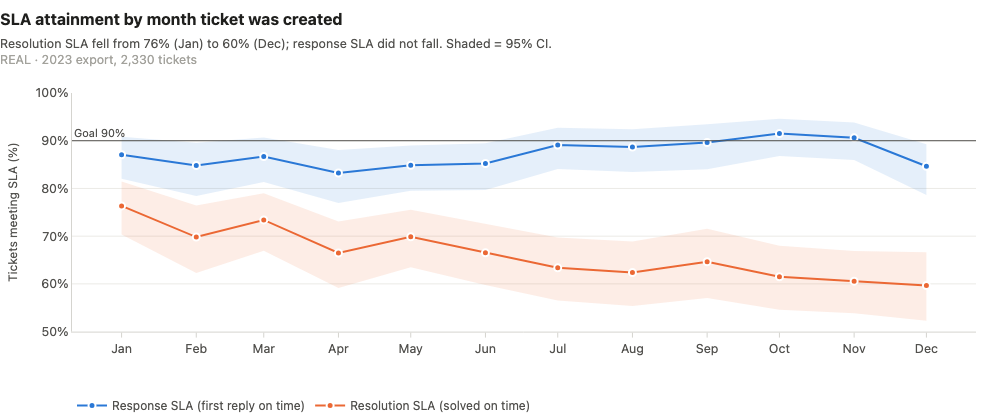

In [10]:
C.fig_sla_trend(monthly, goal)

**What this shows:** resolution SLA (orange) falls from 76.3% of January's tickets to
59.7% of December's, while response SLA (blue) does not fall: it is higher in H2
(89.1%) than in H1 (85.4%). The SLA the Director sees falling is
resolution.

In [11]:
cols = ["tickets", "response_attainment", "resolution_attainment", "resolution_attainment_lo",
        "resolution_attainment_hi", "resolution_median_h", "resolution_p90_h", "share_resolved_over_48h"]
bydim[bydim.dimension.isin(["quarter", "half"])].set_index(["dimension", "segment"])[cols].round(3)

tickets  response_attainment  resolution_attainment  \
dimension segment                                                        
half      H1          1181                0.854                  0.706   
          H2          1149                0.891                  0.620   
quarter   Q1           586                0.863                  0.735   
          Q2           595                0.845                  0.677   
          Q3           560                0.891                  0.634   
          Q4           589                0.891                  0.606   

                   resolution_attainment_lo  resolution_attainment_hi  \
dimension segment                                                       
half      H1                          0.680                     0.731   
          H2                          0.591                     0.647   
quarter   Q1                          0.698                     0.770   
          Q2                          0.639                     0.714   
          Q3                          0.593                     0.673   
          Q4                          0.566                     0.645   

                   resolution_median_h  resolution_p90_h  \
dimension segment                                          
half      H1                    20.290            55.775   
          H2                    23.449           106.028   
quarter   Q1                    20.964            47.106   
          Q2                    19.790            68.225   
          Q3                    22.791           109.011   
          Q4                    24.465           102.691   

                   share_resolved_over_48h  
dimension segment                           
half      H1                         0.112  
          H2                         0.233  
quarter   Q1                         0.090  
          Q2                         0.133  
          Q3                         0.215  
          Q4                         0.250

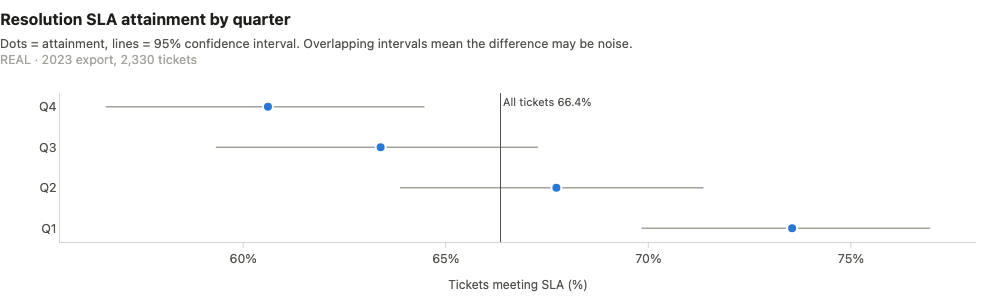

In [12]:
C.fig_breakdown(bydim, "quarter", "resolution", goal)

**What this shows:** each quarter is lower than the one before. Q1 73.5% (95% CI
69.8%-77.0%) and Q4 60.6%
(56.6%-64.5%) have intervals that do not overlap, so the fall is
larger than noise.

### 2. The monthly KPI table

In [13]:
cols = {"tickets": "tickets", "response_attainment": "response SLA", "resolution_attainment": "resolution SLA",
        "resolved_late": "resolved late", "unresolved_overdue": "never resolved",
        "frt_median_min_live": "first reply chat/phone, median min", "frt_median_min_email": "first reply email, median min",
        "resolution_median_h": "resolution median h", "resolution_p90_h": "resolution p90 h",
        "share_resolved_over_48h": "resolved after 48 h", "csat_avg": "CSAT"}
table = monthly.set_index(monthly.created_month.dt.strftime("%b"))[list(cols)].rename(columns=cols)
table.astype({"resolved late": int, "never resolved": int}).round(3)

,tickets,response SLA,resolution SLA,resolved late,never resolved,"first reply chat/phone, median min","first reply email, median min",resolution median h,resolution p90 h,resolved after 48 h,CSAT
created_month,,,,,,,,,,,
Jan,224,0.871,0.763,16,37,1.230,32.016,19.227,46.515,0.080,3.491
Feb,159,0.848,0.698,12,36,1.371,31.984,20.500,47.452,0.098,3.471
Mar,203,0.867,0.734,19,35,1.344,33.230,23.159,47.193,0.095,3.559
Apr,173,0.832,0.665,20,38,1.221,28.835,19.828,55.124,0.133,3.432
May,219,0.849,0.699,21,45,1.266,35.631,17.781,55.782,0.109,3.412
Jun,203,0.852,0.665,28,40,1.468,37.102,21.297,85.796,0.160,3.577
Jul,202,0.891,0.634,36,38,1.331,27.166,21.460,110.399,0.183,3.433
Aug,194,0.887,0.624,38,35,1.273,29.407,25.076,106.144,0.214,3.438
Sep,164,0.896,0.646,37,21,1.213,35.396,23.639,106.574,0.252,3.433


Reading down the columns: first-reply medians barely move all year (chat/phone between 1.0 and
1.5 minutes, email between 27 and 37 minutes) and CSAT stays between
3.41 and 3.63. What moves is resolution: the count resolved late rises from spring onwards,
the 90th-percentile resolution time more than doubles, and the median hardly changes.

### 3. Where in the distribution did resolution slow down?

In [14]:
resolved = fct[fct.is_resolved]
resolved.groupby("created_half")["resolution_h"].describe(percentiles=[0.5, 0.75, 0.9]).round(1)

,count,mean,std,min,50%,75%,90%,max
created_half,,,,,,,,
H1,950.0,28.5,28.3,0.1,20.3,37.4,55.8,146.8
H2,962.0,37.9,36.9,0.0,23.4,46.2,106.0,143.7


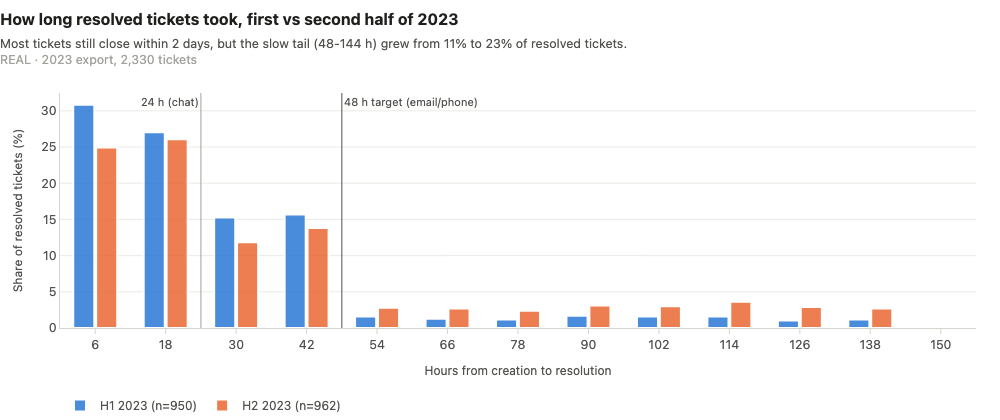

In [15]:
C.fig_resolution_time_hist(fct)

**What this shows:** most resolved tickets still close within two days, and the median moved only from
20.3 h to 23.4 h. What grew is a flat tail between 48 and 144
hours: 11.2% of resolved tickets took more than 48 h in H1,
23.3% in H2. A capacity shortfall would slow every ticket; here a subset of tickets
took a slower path.

### 4. Is the slowdown everywhere? Breakdowns with confidence intervals

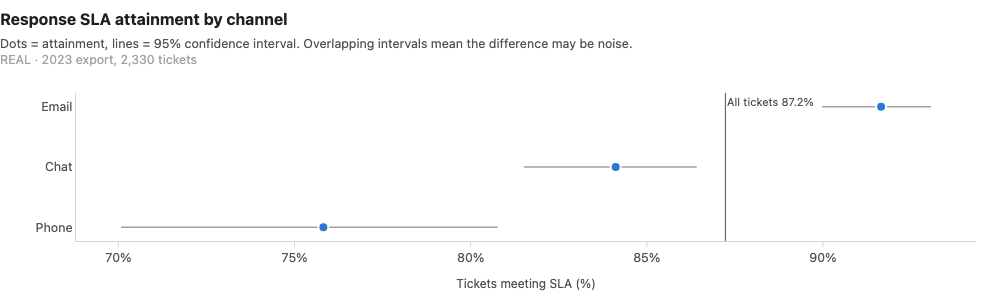

In [16]:
C.fig_breakdown(bydim, "channel", "response", goal)

**What this shows:** response SLA differs by channel because the targets do: phone 75.8%
and chat 84.1% against a 2-minute target, email 91.7% against
60 minutes. Phone's interval sits clearly below the others.

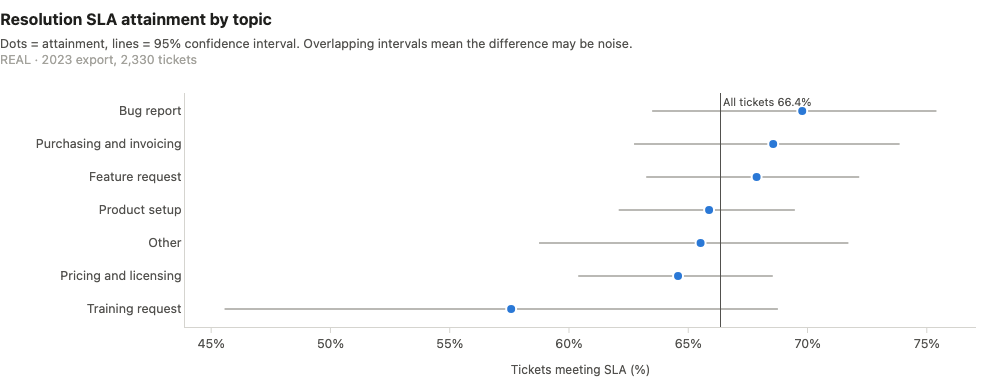

In [17]:
C.fig_breakdown(bydim, "topic", "resolution", goal)

**What this shows:** every topic's interval overlaps the others and the chi-square test finds no difference
(p = 0.501). Training request looks lowest but has only 66 tickets, hence
its wide interval.

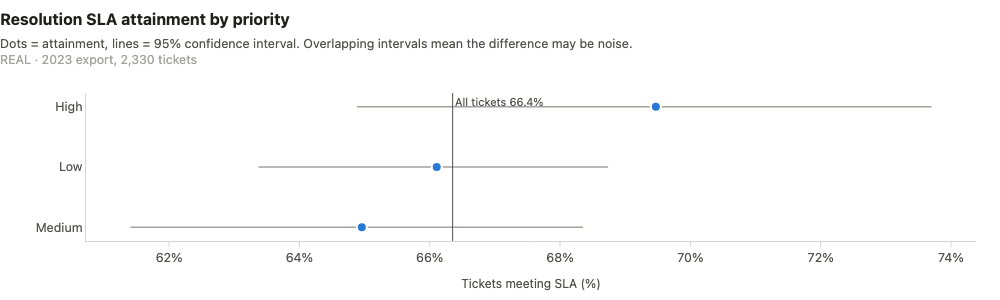

In [18]:
C.fig_breakdown(bydim, "priority", "resolution", goal)

**What this shows:** high-priority tickets are not resolved on time more often than low-priority ones
(p = 0.29), and the SLA targets themselves ignore priority. Priority does not drive
the outcome.

In [19]:
# Resolved-late share (tickets resolved late / all tickets created), H1 vs H2, in every segment
parts = []
for dim in ["channel", "priority", "topic", "agent_group", "product_group", "agent_name"]:
    late = (fct.assign(late=fct.resolution_outcome.eq("Resolved late"))
               .groupby([dim, "created_half"])["late"].mean().unstack())
    parts.append(late.assign(dimension=dim).rename_axis("segment").reset_index())
everywhere = pd.concat(parts, ignore_index=True).set_index(["dimension", "segment"])
everywhere["change_pts"] = 100 * (everywhere["H2"] - everywhere["H1"])
print(f"Resolved-late share rose from H1 to H2 in {(everywhere.change_pts > 0).sum()} of {len(everywhere)} segments")
assert (everywhere.change_pts > 0).all(), "not every segment rose - revisit the text"
everywhere.round(3)

Resolved-late share rose from H1 to H2 in 27 of 27 segments


created_half                                       H1     H2  change_pts
dimension     segment                                                   
channel       Chat                              0.119  0.258      13.906
              Email                             0.082  0.189      10.676
              Phone                             0.112  0.214      10.235
priority      High                              0.105  0.180       7.485
              Low                               0.088  0.216      12.789
              Medium                            0.112  0.241      12.857
topic         Bug report                        0.056  0.248      19.231
              Feature request                   0.096  0.242      14.653
              Other                             0.037  0.234      19.735
              Pricing and licensing             0.139  0.229       9.033
              Product setup                     0.097  0.186       8.932
              Purchasing and invoicing          0.112  0.177       6.498
              Training request                  0.091  0.273      18.182
agent_group   1st line support                  0.098  0.231      13.288
              2nd line support                  0.099  0.176       7.697
product_group Custom software development       0.118  0.226      10.824
              Other                             0.086  0.194      10.840
              Ready to use Software             0.093  0.220      12.710
              Training and Consulting Services  0.088  0.219      13.103
agent_name    Adolpho Messingham                0.108  0.183       7.517
              Bernard Beckley                   0.113  0.225      11.228
              Connor Danielovitch               0.109  0.231      12.202
              Heather Urry                      0.075  0.169       9.354
              Kristos Westoll                   0.116  0.248      13.217
              Michele Whyatt                    0.120  0.175       5.428
              Nicola Wane                       0.083  0.241      15.731
              Sheela Cutten                     0.071  0.208      13.690

The resolved-late share rose in all 27 segments: every channel, priority, topic, tier, product
group and agent. That is the signature of a change in the resolution stage that hit all work alike, not of one
team, queue or person.

In [20]:
# Do segments differ by more than chance? 12 chi-square tests, so adjust them as a family (FDR)
het["q_value"] = kpis.benjamini_hochberg(het.p_value.to_numpy())
het.round(3)

,dimension,sla,chi2,dof,p_value,q_value
0,agent_name,response,7.985,7,0.334,0.464
1,agent_name,resolution,14.435,7,0.044,0.176
2,priority,response,2.028,2,0.363,0.464
3,priority,resolution,2.473,2,0.290,0.464
4,topic,response,6.337,6,0.386,0.464
5,topic,resolution,5.338,6,0.501,0.547
6,channel,response,57.630,2,0.000,0.000
7,channel,resolution,6.248,2,0.044,0.176
8,agent_group,response,0.001,1,0.979,0.979
9,agent_group,resolution,2.672,1,0.102,0.260


Only channel differs clearly, and only for response SLA, where the targets differ by channel. Agents (p =
0.044) and channel for resolution are borderline on their own, but they are two of
twelve tests: after the FDR adjustment both have q = 0.18, not significant. Priority, topic, tier and
product group show nothing.

### 5. Breach hotspots, with a false-discovery-rate check

In [21]:
hot.groupby("sla_type").agg(combinations=("combination", "size"),
                            p_below_5pct=("p_value", lambda p: int((p < 0.05).sum())),
                            survive_fdr=("significant_fdr5", "sum"))

,combinations,p_below_5pct,survive_fdr
sla_type,,,
resolution,1268,55,0
response,1268,90,5


Raw p-values would flag 90 response and 55 resolution combinations; about
63 per SLA would pass by chance alone. After the FDR correction 5
response and 0 resolution combinations remain:

In [22]:
(hot.query("sla_type == 'response' and significant_fdr5")[["combination", "n", "breaches", "breach_rate", "q_value"]]
    .astype({"breaches": int}).round(4))

,combination,n,breaches,breach_rate,q_value
1268,Phone,244,59,0.2418,0.0011
1270,Phone + 1st line support,196,48,0.2449,0.0036
1272,Phone + Low priority,134,33,0.2463,0.0342
1282,Phone + Feature request,43,17,0.3953,0.0041
1292,Phone + Feature request + 1st line support,36,15,0.4167,0.0048


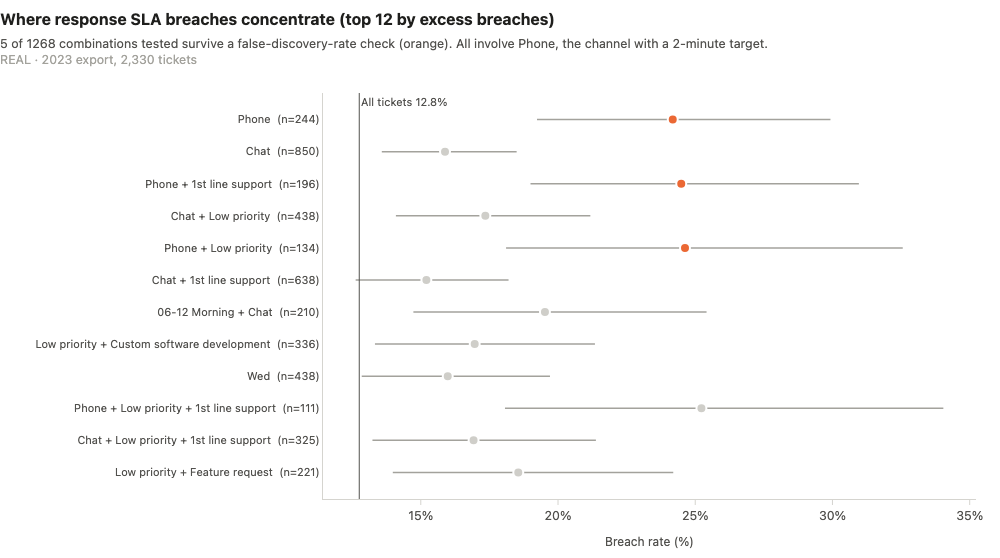

In [23]:
C.fig_hotspots(hot, "response")

**What this shows:** the combinations that survive (orange) are all Phone or a slice of Phone; all
5 are listed in the table above and three of them make this top 12. That is one
finding, not five: phone misses its 2-minute target on
24.2% of tickets. The grey rows look bad on raw rates but are consistent with
chance once 1,268 tests are allowed for.

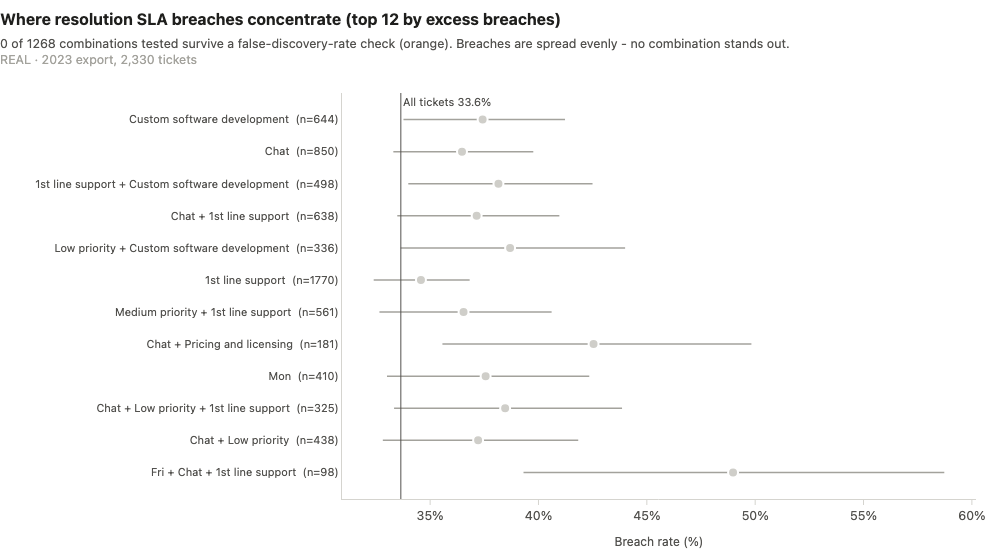

In [24]:
C.fig_hotspots(hot, "resolution")

**What this shows:** no combination survives for resolution SLA. The highest raw breach rates sit in small cells
consistent with chance, which is why we do not report a "Monday morning + billing + high priority" style hotspot.
Together with the segment table above: the resolution slowdown is spread evenly.

### 6. Agent scorecard

In [25]:
agents[["agent_name", "agent_group", "tickets", "resolution_attainment", "resolution_attainment_lo",
        "resolution_attainment_hi", "resolution_attainment_h1", "resolution_attainment_h2"]].round(3)

,agent_name,agent_group,tickets,resolution_attainment,resolution_attainment_lo,resolution_attainment_hi,resolution_attainment_h1,resolution_attainment_h2
0,Nicola Wane,1st line support,367,0.638,0.587,0.685,0.678,0.599
1,Sheela Cutten,1st line support,364,0.695,0.646,0.740,0.750,0.631
2,Bernard Beckley,1st line support,359,0.660,0.610,0.707,0.706,0.615
3,Connor Danielovitch,1st line support,347,0.617,0.565,0.666,0.655,0.578
4,Kristos Westoll,1st line support,333,0.661,0.608,0.709,0.744,0.571
5,Adolpho Messingham,2nd line support,197,0.645,0.576,0.708,0.667,0.625
6,Michele Whyatt,2nd line support,186,0.677,0.607,0.740,0.614,0.728
7,Heather Urry,2nd line support,177,0.763,0.695,0.819,0.802,0.704


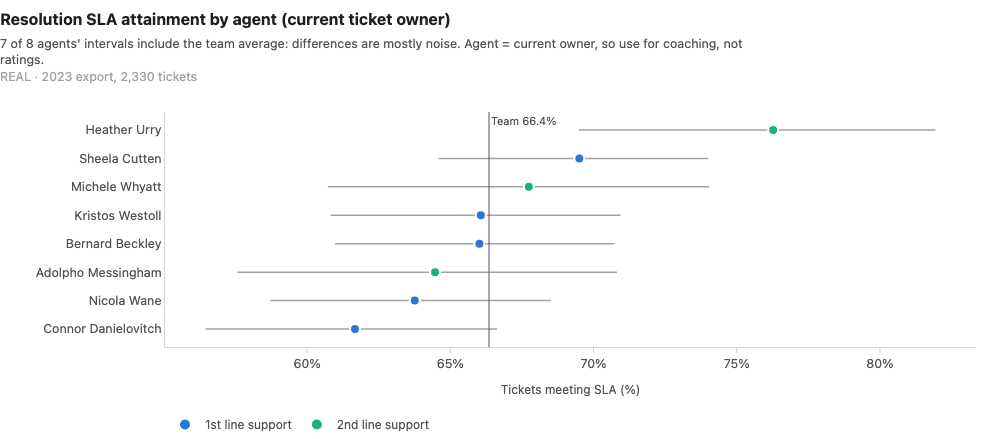

In [26]:
C.fig_agent_scorecard(agents, "resolution")

**What this shows:** agents range from 61.7% to 76.3%
with overlapping intervals; the spread is not significant once the number of tests is accounted for (q =
0.18 above). 7 of 8 agents declined from H1 to H2: the slowdown is
team-wide. `agent_name` is the ticket's current owner, not necessarily who did the work, so this view is for
coaching conversations, not ratings.

### 7. How late are first-response breaches?

In [27]:
lateness.round(2)

,channel,breaches,never_answered,median_minutes_late,p25_minutes_late,p75_minutes_late,share_over_60_min_late
0,Chat,135,4,2.11,1.04,2.96,0.01
1,Email,103,14,209.84,118.40,297.23,0.77
2,Phone,59,0,1.76,0.89,3.02,0.03


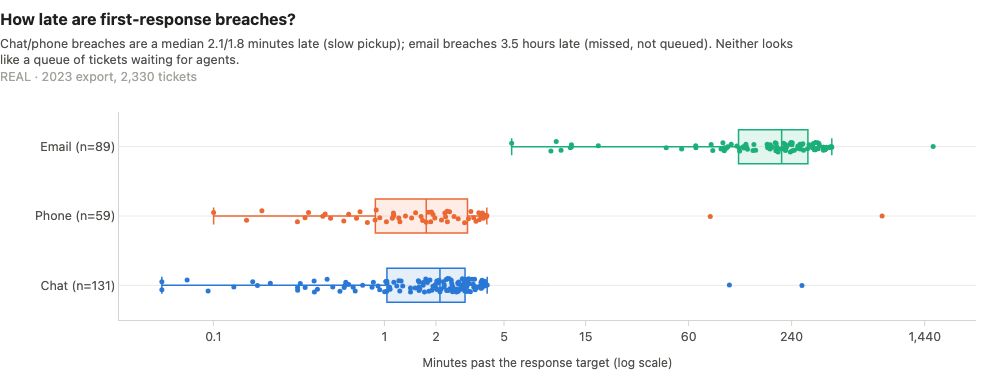

In [28]:
C.fig_breach_lateness(fct)

**What this shows:** chat and phone breaches miss the 2-minute target by a median
2.11 and 1.76 minutes: live contacts picked
up slowly. Email breaches are a median 210 minutes (about
3.5 hours) late, only 9.7% are
near-misses, and 14 were never answered: those emails were missed, not queued.
Neither pattern looks like tickets waiting in a queue for a free agent. Email lateness is an alerting problem,
not a queue.

### Cross-check against `reports/key_numbers.json`

Every headline number above, recomputed in this notebook (SQL results, `support_ops.rca` tests and the tickets
themselves):

In [29]:
def crosscheck(recomputed):
    """Recomputed numbers must equal reports/key_numbers.json, to the rounding stored there."""
    rows = []
    for key, value in recomputed.items():
        stored, value = kn[key], (value.item() if hasattr(value, "item") else value)
        if isinstance(stored, (int, float)) and not isinstance(stored, bool):
            frac = repr(stored).partition(".")[2]                # 0.0271 -> 4 decimals, 202.0 -> 0
            decimals = 0 if frac in ("", "0") else len(frac)
            tol = max(0.5 * 10 ** -decimals, 1e-5 * abs(stored)) + 1e-9   # stored rounding or float noise
            ok = abs(float(value) - stored) <= tol
        else:
            ok = value == stored
        shown = round(value, 6) if isinstance(value, float) else value
        rows.append({"key": key, "key_numbers.json": stored, "recomputed here": shown, "match": ok})
    out = pd.DataFrame(rows, dtype=object)                       # keep ints as ints in the display
    bad = out[~out["match"].astype(bool)]
    assert bad.empty, bad.to_string()
    return out

In [30]:
bd = bydim.set_index(["dimension", "segment"])
q_sql = quarterly                                              # straight from the DuckDB query in Method
het_fresh = rca.heterogeneity(fct).set_index(["dimension", "sla"]).p_value
late_fresh = rca.breach_lateness(fct).set_index("channel")
email_breach = fct[fct.channel.eq("Email") & fct.response_sla_met.eq(False).fillna(False).astype(bool)]
minutes_late = email_breach.frt_min - email_breach.response_target_min
resolved = fct[fct.is_resolved]
fdr = {s: int((kpis.benjamini_hochberg(g.p_value.to_numpy()) < 0.05).sum()) for s, g in hot.groupby("sla_type")}
crosscheck({
    "response_sla_2023": fct.response_sla_met.mean(),
    "response_evaluable": fct.response_sla_met.notna().sum(),
    "resolution_sla_2023": fct.resolution_sla_met.mean(),
    "resolution_sla_q1": q_sql.loc["Q1", "resolution_attainment"],
    "resolution_sla_q4": q_sql.loc["Q4", "resolution_attainment"],
    "resolution_sla_q1_lo": q_sql.loc["Q1", "resolution_ci_lo"],
    "resolution_sla_q1_hi": q_sql.loc["Q1", "resolution_ci_hi"],
    "resolution_sla_q4_lo": q_sql.loc["Q4", "resolution_ci_lo"],
    "resolution_sla_q4_hi": q_sql.loc["Q4", "resolution_ci_hi"],
    "resolution_sla_jan": monthly.resolution_attainment.iloc[0],
    "resolution_sla_dec": monthly.resolution_attainment.iloc[-1],
    "response_sla_h1": fct.loc[fct.created_half == "H1", "response_sla_met"].mean(),
    "response_sla_h2": fct.loc[fct.created_half == "H2", "response_sla_met"].mean(),
    "response_sla_email": fct.loc[fct.channel == "Email", "response_sla_met"].mean(),
    "response_sla_chat": fct.loc[fct.channel == "Chat", "response_sla_met"].mean(),
    "response_sla_phone": fct.loc[fct.channel == "Phone", "response_sla_met"].mean(),
    "phone_response_breach_rate": 1 - bd.loc[("channel", "Phone"), "response_attainment"],
    "resolution_median_h_h1": fct.loc[fct.created_half == "H1", "resolution_h"].median(),
    "resolution_median_h_h2": fct.loc[fct.created_half == "H2", "resolution_h"].median(),
    "resolution_p90_h_jan": monthly.resolution_p90_h.iloc[0],
    "resolution_p90_h_dec": monthly.resolution_p90_h.iloc[-1],
    "share_resolved_over_48h_h1": resolved.loc[resolved.created_half == "H1", "resolution_h"].gt(48).mean(),
    "share_resolved_over_48h_h2": resolved.loc[resolved.created_half == "H2", "resolution_h"].gt(48).mean(),
    "hotspots_tested_per_sla": (hot.sla_type == "response").sum(),
    "hotspots_significant_response": fdr["response"],
    "hotspots_significant_resolution": fdr["resolution"],
    "rca_priority_p_resolution": het_fresh.loc[("priority", "resolution")],
    "rca_topic_p_resolution": het_fresh.loc[("topic", "resolution")],
    "rca_agent_p_resolution": het_fresh.loc[("agent_name", "resolution")],
    "agent_resolution_sla_min": agents.resolution_attainment.min(),
    "agent_resolution_sla_max": agents.resolution_attainment.max(),
    "agents_declined_h1_to_h2": (agents.resolution_attainment_change < 0).sum(),
    "late_email_breach_median_min_late": late_fresh.loc["Email", "median_minutes_late"],
    "late_chat_breach_median_min_late": late_fresh.loc["Chat", "median_minutes_late"],
    "late_phone_breach_median_min_late": late_fresh.loc["Phone", "median_minutes_late"],
    "email_breaches": len(email_breach),
    "email_breach_never_answered": email_breach.frt_min.isna().sum(),
    "email_breach_near_miss_share": ((minutes_late > 0) & (minutes_late <= 60)).sum() / len(email_breach),
    "dq_response_flag_mismatches": fct.response_flag_mismatch.sum(),
    "dq_resolution_flag_mismatches": fct.resolution_flag_mismatch.sum(),
    "csat_breached": fct.loc[~fct.resolution_sla_met, "csat_score"].mean(),
    "csat_met": fct.loc[fct.resolution_sla_met, "csat_score"].mean(),
})

,key,key_numbers.json,recomputed here,match
0,response_sla_2023,0.872423,0.872423,True
1,response_evaluable,2328,2328,True
2,resolution_sla_2023,0.663519,0.663519,True
3,resolution_sla_q1,0.735495,0.735495,True
4,resolution_sla_q4,0.606112,0.606112,True
5,resolution_sla_q1_lo,0.698333,0.698333,True
6,resolution_sla_q1_hi,0.76959,0.769589,True
7,resolution_sla_q4_lo,0.566086,0.566087,True
8,resolution_sla_q4_hi,0.644763,0.644762,True
9,resolution_sla_jan,0.763393,0.763393,True


## Limitations

- **Export provenance.** This is a public data-challenge dataset. On-time response times are spread evenly
  inside the target window, CSAT is unrelated to breaches (3.6 for breached vs 3.49
  for met tickets), resolution times are capped near 6 days and resolution clocks ignore weekends. We do not
  over-read relationships between fields.
- **Agent = current owner.** `agent_name` is who owns the ticket now, not necessarily who worked it, so agent
  comparisons are for coaching, not ratings.
- **No status history.** We can see *that* a subset of tickets took a slow path, not *where* the time went
  (waiting on the customer, engineering or tier 2).
- **Hotspot p-values are approximate.** Combinations overlap and are tested against an overall rate that
  includes them; the FDR step guards against reading noise as a hotspot but is not exact.
- **Cohorts by creation month.** Tickets created in the last days of December had less time to be resolved
  before the snapshot; with resolution times capped near 6 days this affects only the last week.
- **Two tickets are excluded from response SLA** because their first reply is time-stamped before creation.

## Recommendations

- **Support Director + tier-2 lead, with Ops Analytics - find and reverse the resolution slow path.** Tickets
  resolved late rose from 9.8% to 21.8% of all tickets, in every
  segment. *Impact:* back at the H1 rate, on-time resolution would be near
  74% (a target, not a forecast). *Measure:* time in each status from
  the ticket audit log; resolved-late share back to 10% or less; 90th-percentile resolution time 48 h or less.
  *Risk:* the cause may sit outside support (a release, tooling, a dependency); it needs status-history data.
- **Team leads + support-tooling owner - pilot the pickup fixes:** a 45-minute "unanswered email" alert and push
  routing for chat and phone. *Impact:* email breaches are hours late, so an alert targets them directly; if it
  caught half of them, response SLA would rise by about 2.2 points
  (illustration; the catch rate is unknown until piloted). *Measure:* share of emails answered within 60 min;
  alerts fired vs answered within 15 min. *Risk:* only 9.7% of email
  breaches are near-misses; alert fatigue.
- **Team leads - use the agent scorecard for coaching only.** Differences between agents are within noise and
  7 of 8 declined together. *Measure:* none at individual level until a work log
  exists. *Risk:* rating people on current-owner data would be unfair and would miss the system-wide cause.
- **Ops Analytics - report response and resolution SLA separately, from timestamps, with intervals.** A single
  blended "SLA" hides that only resolution fell, and the raw flags disagree with timestamps on
  15 tickets. *Measure:* the monthly pack
  shows both SLAs with Wilson intervals. *Risk:* low - it is a reporting change.